多层感知机

muiltilayer

MLP 是一种 前馈神经网络（Feedforward Neural Network），信息从输入层 → 隐藏层 → 输出层单向流动，无循环结构。 
由多个神经元组成，相邻层之间 全连接（Fully Connected）。 通过非线性激活函数（如 ReLU、Sigmoid、Tanh）实现对复杂函数的逼近

激活函数：ReLU,sigmoid


tensor([3.3535e-04, 3.7061e-04, 4.0957e-04, 4.5262e-04, 5.0020e-04, 5.5278e-04,
        6.1088e-04, 6.7508e-04, 7.4603e-04, 8.2442e-04, 9.1105e-04, 1.0068e-03,
        1.1125e-03, 1.2294e-03, 1.3585e-03, 1.5012e-03, 1.6588e-03, 1.8329e-03,
        2.0253e-03, 2.2378e-03, 2.4726e-03, 2.7320e-03, 3.0184e-03, 3.3348e-03,
        3.6842e-03, 4.0701e-03, 4.4963e-03, 4.9668e-03, 5.4863e-03, 6.0598e-03,
        6.6929e-03, 7.3915e-03, 8.1626e-03, 9.0133e-03, 9.9518e-03, 1.0987e-02,
        1.2128e-02, 1.3387e-02, 1.4774e-02, 1.6302e-02, 1.7986e-02, 1.9840e-02,
        2.1881e-02, 2.4127e-02, 2.6597e-02, 2.9312e-02, 3.2295e-02, 3.5571e-02,
        3.9166e-02, 4.3107e-02, 4.7426e-02, 5.2154e-02, 5.7324e-02, 6.2973e-02,
        6.9138e-02, 7.5858e-02, 8.3173e-02, 9.1123e-02, 9.9750e-02, 1.0910e-01,
        1.1920e-01, 1.3011e-01, 1.4185e-01, 1.5447e-01, 1.6798e-01, 1.8243e-01,
        1.9782e-01, 2.1416e-01, 2.3148e-01, 2.4974e-01, 2.6894e-01, 2.8905e-01,
        3.1003e-01, 3.3181e-01, 3.5434e-

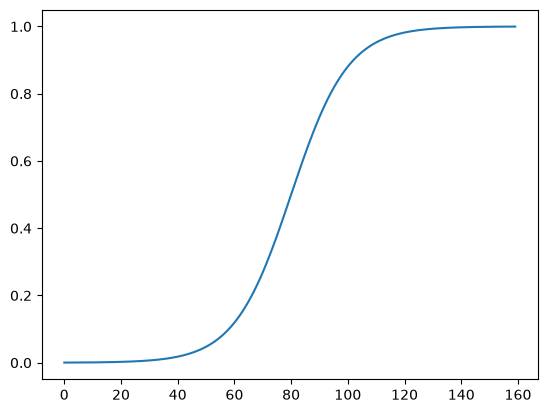

In [11]:
import torch
import matplotlib.pyplot as plt
x=torch.arange(-8,8,0.1,dtype=torch.float,requires_grad=True)
y=torch.sigmoid(x)
print(y,y.detach(),id(y),id(y.detach()))

plt.plot(y.detach())

tensor实例的detach方法，返回一个无梯度追踪的tensor实例

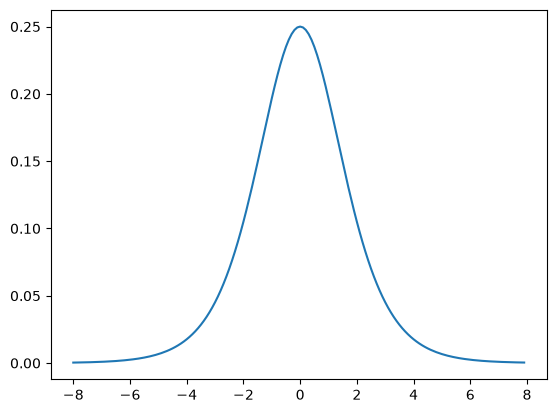

In [ ]:
#x.grad.data.zero_() # 梯度清零

y.backward(torch.ones_like(x),retain_graph=True) # y不是标量scaler

plt.plot(x.detach(),x.grad)


单隐藏层

nn.Parameter类用于创建参数

nn.CrossEntropyLoss类用于求交叉熵损失
    reduction关键词参数控制损失函数的输出形式，mean(返回所有样本的损失平均值)，sum，none

In [ ]:
from torch import nn
import torch
num_inputs, num_outputs, num_hiddens = 784, 10, 256

W1 = nn.Parameter(torch.randn(
    num_inputs, num_hiddens, requires_grad=True) * 0.01)
b1 = nn.Parameter(torch.zeros(num_hiddens, requires_grad=True))
W2 = nn.Parameter(torch.randn(
    num_hiddens, num_outputs, requires_grad=True) * 0.01)
b2 = nn.Parameter(torch.zeros(num_outputs, requires_grad=True))

params = [W1, b1, W2, b2]

from llm_kernel import d2l
from llm_kernel.NeuralNetwork import relu

def net(X):
    X = d2l.reshape(X, (-1, num_inputs))
    H = relu(X@W1 + b1)  # 这里“@”代表矩阵乘法
    return (H@W2 + b2)

loss=nn.CrossEntropyLoss(reduction='none') 

train_iter,test_iter=d2l.load_data_fashion_mnist(256)

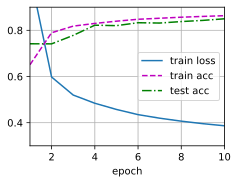

In [3]:
num_epochs, lr = 10, 0.1
updater = torch.optim.SGD(params, lr=lr)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, updater)

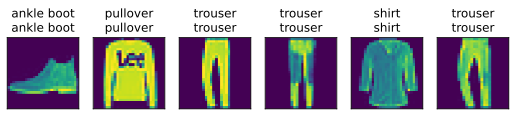

In [4]:
d2l.predict_ch3(net, test_iter)